# Slopes, bends and jerk on the 8 plant stages

All slope and jerk calculations of 2026-11-03/04, run from `scripts/slopes_jerk.py` on the 39 day files with the
**decided plant stages** (`operating_states.ipynb` §12). The notebook calls the same functions as the script, shows the
tables and draws the curves; each section also writes its files to `03_data_analysis/slopes_jerk/`.

| § | What | Function |
|---|---|---|
| 1 | Stack slope per stage, per 100 °C band, onset of the move | `stack_block_slopes`, `stack_rate_table`, `onset_lags` |
| 2 | Heat-up and air-flow cooling runs (milestones, curves) | `heatup_runs`, `cooling_runs` |
| 3 | Heater and gas-path temperatures per stage | `other_curve_slopes` |
| 4 | Every logged column that changes inside a stage | `all_column_slopes` |
| 5 | Stage borders: slope before/after, bend, acceleration, jerk, bend time | `border_table`, `border_type_curves` |
| 6 | Leaving hot standby: how fast the stack cools | `stage_exits` |

**Words used**

* **Slope** – straight line through the readings, in units per hour (°C/h for temperatures).
* **Block** – one unbroken stretch of a stage (a logger gap > 2 min starts a new block).
* **Stage groups** – the 8 plant stages, with *Air-flow cooling* split into normal air (6000 ln/min) and strong air
  (≥ 7000, i.e. 8000–10000). *Shutdown* counts only while the stack is still above 100 °C (air-off cooling).
* **Bend** – slope after a stage change minus slope before (each side a 30-min line).
* **Acceleration / jerk** – how fast the slope changes (°C/h per min) and how fast that changes (°C/h per min²);
  peaks are taken within ±15 min of the stage change.
* **Bend time** – minutes the smoothed slope takes to go from 10 % to 90 % of the way from the old to the new slope.

In [1]:
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

sys.path.insert(0, "scripts")   # helper modules live in 03_data_analysis/scripts/
import slopes_jerk as sj

warnings.filterwarnings("ignore")   # empty-slice / datetime-round notices only
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e3e3e3", "grid.linewidth": 0.6, "lines.linewidth": 2, "font.size": 9})
# categorical order as in heater_temperatures.ipynb; warm = heating (orange), cool = cooling (blue)
BLUE, ORANGE, GREEN, YELLOW, PINK, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#8a8a8a"
DIV = LinearSegmentedColormap.from_list("cool_warm", [BLUE, "#ececec", ORANGE])
OUT = sj.OUT
OUT.mkdir(parents=True, exist_ok=True)


def heat(t, title, lim=None, fmt="{:+.0f}", note="°C/h"):
    # value table as a diverging heat map: blue = falling, grey = flat, orange = rising
    v = t.to_numpy(float)
    lim = lim or np.nanmax(np.abs(v))
    fig, ax = plt.subplots(figsize=(0.95 * t.shape[1] + 3, 0.38 * t.shape[0] + 1.3))
    ax.imshow(v, cmap=DIV, vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(t.shape[1]), [str(c).replace(", ", ",\n") for c in t.columns], rotation=0, fontsize=8)
    ax.set_yticks(range(t.shape[0]), t.index)
    ax.xaxis.tick_top()
    for (i, j), x in np.ndenumerate(v):
        if np.isfinite(x):
            ax.text(j, i, fmt.format(x), ha="center", va="center", fontsize=8, color="#1a1a1a")
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(f"{title}  ({note}; blue = falling, orange = rising)", loc="left", fontsize=10, pad=34)
    plt.show()


d = sj.load_frame()          # cached 1-min table; sj.load_frame(rebuild=True) re-reads the day files
print(d.shape, d.index[0], "→", d.index[-1])

(55584, 32) 2025-10-30 00:00:00 → 2026-03-30 23:59:00


## 1. Stack temperature slope per stage

One straight line through every stage block (≥ 20 min). The table and chart use the clean blocks only: heat-up blocks
that start at 00:00 are file cuts, the hot *Heat-up air* block of 2026-03-22 (274 °C, 9.5 h at air 10000) is left out,
and *Shutdown* counts only above 100 °C.

In [2]:
blocks = sj.stack_block_slopes(d)
summary = sj.summarise_blocks(blocks)
blocks.to_csv(OUT / "stack_block_slopes.csv", index=False)
summary.to_csv(OUT / "stack_slope_summary.csv")
summary

,runs,median,low,high
group,,,,
Heat-up air,12,30.6,-1.5,48.1
Heat-up N₂+H₂,12,38.8,8.1,58.9
Hot standby,20,0.2,-28.1,18.3
Fuel switch,3,39.4,19.7,42.0
Part load,6,99.8,55.7,124.4
"Air-flow cooling, normal air",10,-18.6,-48.2,-4.1
"Air-flow cooling, strong air",5,-40.6,-50.3,-18.5
Shutdown,7,-2.0,-6.6,-1.5


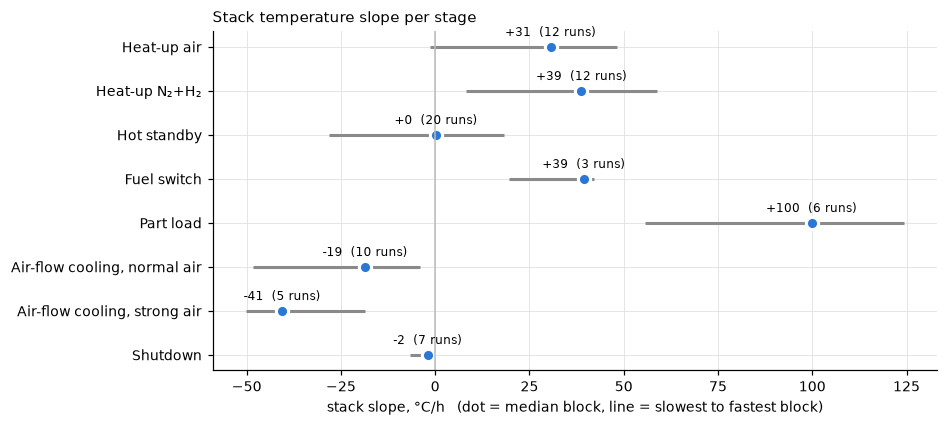

In [3]:
s = summary.iloc[::-1]
y = np.arange(len(s))
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.hlines(y, s["low"], s["high"], color=GRAY, lw=2)
ax.plot(s["median"], y, "o", color=BLUE, ms=8, mec="white", mew=2)
for yi, (m, n) in enumerate(zip(s["median"], s["runs"])):
    ax.annotate(f"{m:+.0f}  ({n} runs)", (m, yi), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8)
ax.axvline(0, color="#bbb", lw=1)
ax.set_yticks(y, s.index)
ax.set_xlabel("stack slope, °C/h   (dot = median block, line = slowest to fastest block)")
ax.set_title("Stack temperature slope per stage", loc="left", fontsize=10)
plt.show()

### 1.1 Slope by temperature band

A 30-min centred rate at every minute (only where the 30 minutes are unbroken), median per stage group and 100 °C band.
Cells with fewer than 30 minutes are left empty. This shows that the speed depends on the temperature: heat-up slows as
the stack gets hotter, cooling slows as it gets colder.

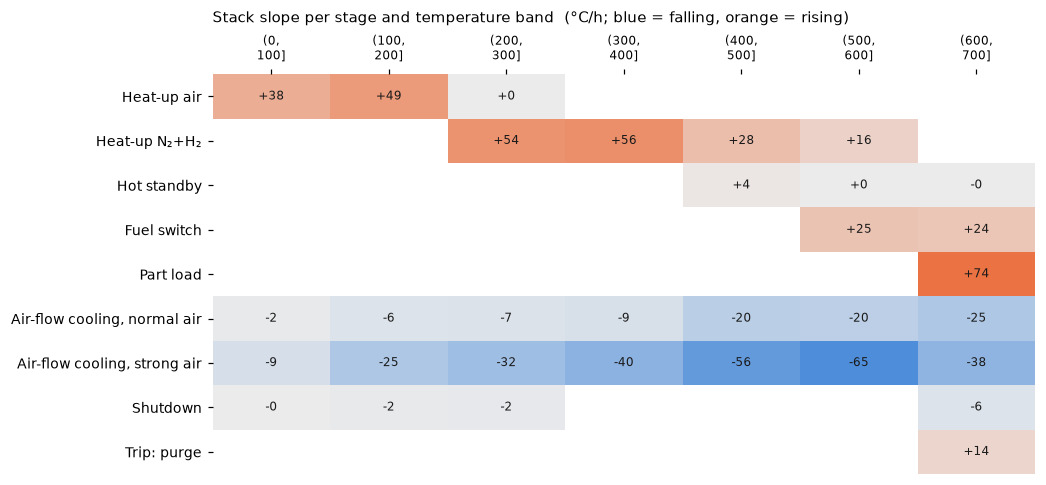

In [4]:
rates = sj.stack_rate_table(d)
rates.to_csv(OUT / "stack_rate_by_band.csv", index=False)
tab = rates.pivot(index="group", columns="band", values="median").reindex([g for g in sj.GROUPS if g in set(rates.group)])
heat(tab, "Stack slope per stage and temperature band", lim=80)

### 1.2 How long until the stack starts to move

Minutes from the start of a stage until the stack has moved 2 °C the expected way (up in heat-up, down in cooling).

In [5]:
onset = sj.onset_lags(d)
onset.to_csv(OUT / "stack_onset_lags.csv", index=False)
onset.groupby("stage").onset_min.agg(runs="count", median="median", low="min", high="max")

,runs,median,low,high
stage,,,,
Air-flow cooling,11,7.0,4.0,16.0
Heat-up N₂+H₂,12,3.0,2.0,46.0
Heat-up air,11,32.0,5.0,116.0


## 2. Heat-up and cooling runs

**Heat-up:** every *Heat-up air* start, followed until the plant leaves the two heat-up stages (max 20 h). Cold starts
are runs that begin below 50 °C. **Cooling:** every *Air-flow cooling* start above 400 °C, followed while it lasts
(max 12 h).
The flat orange line at 274 °C in the heat-up chart is the odd 2026-03-22 run (labelled *Heat-up air* for 9.5 h at air
10000); it is kept here but left out of the stage slopes in §1.

In [6]:
hu, hu_curves = sj.heatup_runs(d)
co, co_curves = sj.cooling_runs(d)
hu.to_csv(OUT / "heatup_runs.csv", index=False)
co.to_csv(OUT / "cooling_runs.csv", index=False)
print("Cold starts, median hours:", hu[hu.T_start_C < 50][["h_to_gas_switch", "h_to_100C", "h_to_200C", "h_to_300C", "h_to_500C"]].median().round(1).to_dict())
hu.round(2)

Cold starts, median hours: {'h_to_gas_switch': 4.6, 'h_to_100C': 2.3, 'h_to_200C': 4.5, 'h_to_300C': 6.3, 'h_to_500C': 9.2}


,start,T_start_C,hours,T_end_C,h_to_gas_switch,slope_C_per_h,h_to_100C,h_to_200C,h_to_300C,h_to_500C
0,2025-10-30 11:29:00,139.48,3.03,199.14,2.82,27.44,NaN,2.75,NaN,NaN
1,2025-11-13 10:47:00,10.11,10.75,471.67,5.50,44.24,1.68,4.47,7.23,NaN
2,2026-01-30 10:10:00,4.10,9.00,240.35,NaN,26.15,2.65,7.47,NaN,NaN
3,2026-01-31 08:09:00,176.02,9.63,571.79,2.00,47.81,NaN,1.37,3.38,7.20
4,2026-02-13 14:32:00,14.54,12.43,495.53,4.63,45.62,2.50,4.47,6.28,NaN
5,2026-02-17 16:56:00,191.72,9.38,495.25,1.78,39.13,NaN,NaN,3.15,NaN
6,2026-03-01 09:05:00,27.53,12.63,494.11,4.95,44.95,2.77,4.75,6.58,NaN
7,2026-03-12 11:34:00,29.35,13.65,566.72,3.87,44.47,1.68,3.68,5.50,9.23
8,2026-03-17 14:56:00,57.69,5.20,188.40,NaN,34.93,2.70,4.75,NaN,NaN
9,2026-03-18 07:06:00,168.73,10.35,566.78,1.65,46.84,NaN,1.73,3.03,6.47


In [7]:
co.round(1)

,start,T_start_C,air,hours,T_end_C,slope_C_per_h,drop_first_h_C,drop_3h_C
0,2025-11-13 21:32:00,471.7,1259.9,12.0,340.9,-11.1,11.4,40.8
1,2026-02-04 02:01:00,508.9,6000.4,12.0,260.6,-20.3,28.4,78.8
2,2026-02-16 10:37:00,509.6,6000.1,12.0,285.1,-18.4,27.9,77.8
3,2026-02-18 18:52:00,579.1,6000.0,5.1,442.4,-27.0,29.7,85.3
4,2026-03-04 17:56:00,613.6,8000.0,6.0,336.3,-50.0,31.1,147.2
5,2026-03-13 14:01:00,689.2,6000.0,10.0,443.6,-24.7,30.2,81.3
6,2026-03-19 16:10:00,650.7,6000.0,12.0,477.3,-13.6,25.6,67.7
7,2026-03-20 16:24:00,572.2,10000.1,7.6,280.5,-40.6,53.0,182.0
8,2026-03-25 15:35:00,663.5,9000.0,12.0,100.2,-49.0,57.4,185.2
9,2026-03-30 13:33:00,626.8,7999.9,7.4,260.7,-53.7,45.6,190.3


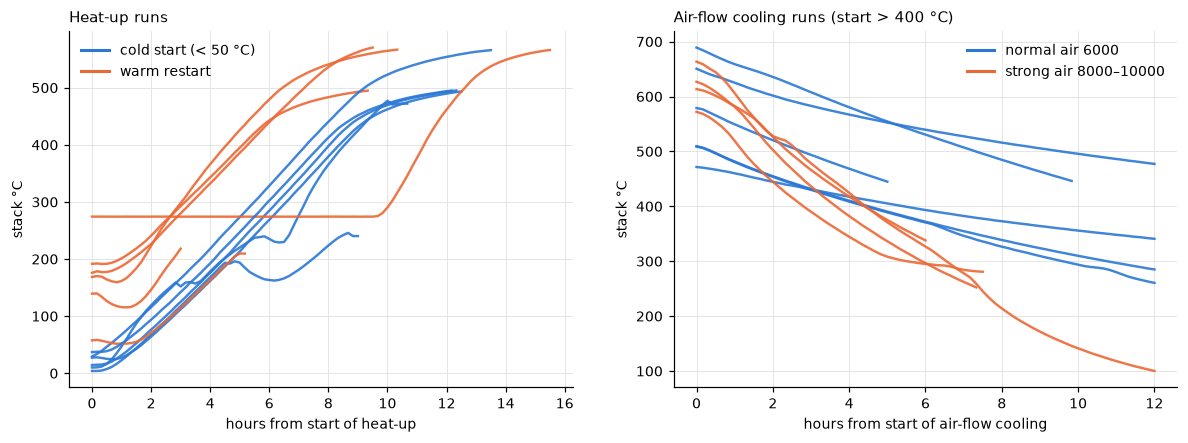

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for start, c in hu_curves.items():
    c = np.array(c)
    cold = hu.loc[hu.start == pd.Timestamp(start), "T_start_C"].iloc[0] < 50
    axs[0].plot(c[:, 0], c[:, 1], color=BLUE if cold else ORANGE, lw=1.6, alpha=.9)
axs[0].plot([], [], color=BLUE, label="cold start (< 50 °C)")
axs[0].plot([], [], color=ORANGE, label="warm restart")
axs[0].set(xlabel="hours from start of heat-up", ylabel="stack °C", title="Heat-up runs")
for start, c in co_curves.items():
    c = np.array(c)
    strong = co.loc[co.start == pd.Timestamp(start), "air"].iloc[0] >= sj.STRONG_AIR
    axs[1].plot(c[:, 0], c[:, 1], color=ORANGE if strong else BLUE, lw=1.6, alpha=.9)
axs[1].plot([], [], color=BLUE, label="normal air 6000")
axs[1].plot([], [], color=ORANGE, label="strong air 8000–10000")
axs[1].set(xlabel="hours from start of air-flow cooling", ylabel="stack °C", title="Air-flow cooling runs (start > 400 °C)")
for a in axs:
    a.legend(frameon=False, loc="best")
    a.title.set_fontsize(10); a.title.set_ha("left"); a.title.set_x(0)
plt.show()

## 3. Heater and gas-path temperatures per stage

Same block line fit for the heater control thermocouples (ERH, EAGH, EAOH1–3) and the gas-path probes (cathode inlet,
reformer outlet, anode outlet, recycle inlet), blocks ≥ 60 min. *first 30 min* = change from the block start to minutes
25–35; *onset* = minutes until a 2 °C move the expected way.

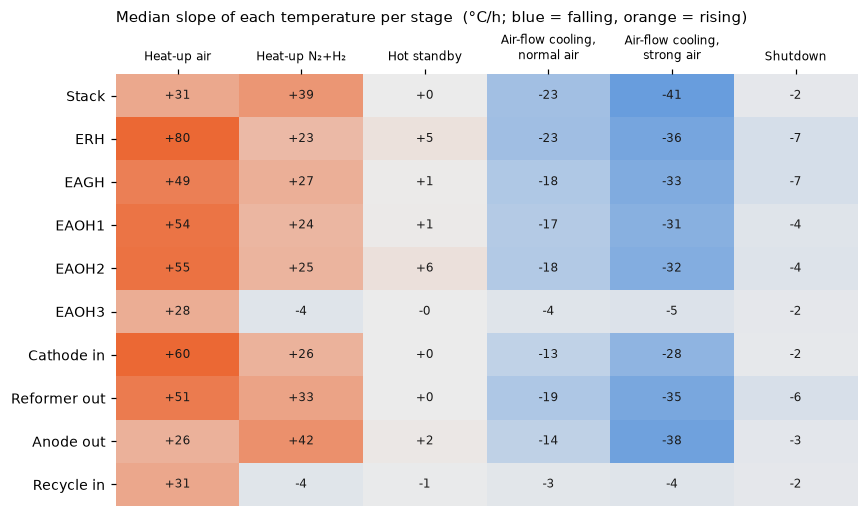

In [9]:
tblocks, tsum = sj.other_curve_slopes(d)
tblocks.to_csv(OUT / "temperature_block_slopes.csv", index=False)
tsum.to_csv(OUT / "temperature_slope_summary.csv", index=False)
heat(tsum.pivot(index="curve", columns="group", values="median").dropna(axis=1, how="all"),
     "Median slope of each temperature per stage", lim=60)

In [10]:
tsum.pivot(index="curve", columns="group", values="onset_min").dropna(axis=1, how="all")

group,Heat-up air,Heat-up N₂+H₂,Hot standby,"Air-flow cooling, normal air","Air-flow cooling, strong air",Shutdown
curve,,,,,,
Stack,32.0,3.0,27.5,8.0,5.0,57.0
ERH,3.0,5.0,9.5,1.0,3.0,6.5
EAGH,4.0,83.0,9.5,4.0,5.0,19.0
EAOH1,5.0,109.0,12.5,2.0,3.0,8.5
EAOH2,3.0,129.5,13.0,2.0,9.0,6.0
EAOH3,3.5,2.0,317.0,3.0,4.0,16.0
Cathode in,3.0,2.0,115.5,4.0,6.0,63.0
Reformer out,7.5,4.5,8.5,3.0,6.0,21.5
Anode out,9.0,2.0,10.0,10.0,9.0,44.0


## 4. Every logged column that changes inside a stage

All raw logger columns as 1-min means (`all_columns_1min.parquet`, cached). Kept: columns that are live (more than two
values, ≥ 5 % coverage) and are measurements, setpoints, controller outputs or insulation monitors (status bits, alarms,
operating-mode and counter columns dropped; values above 10⁷ are logger junk). A column *changes with time* if inside at
least one stage group it moves more than 2 % of its range (5–95 % spread in a block); the range is the 0.5–99.5 % spread
over all days. Slopes are per hour in the column's own unit and as % of its range per hour.

In [11]:
L, info = sj.all_column_slopes(d, sj.load_all_columns())
L.to_csv(OUT / "all_column_slopes_long.csv", index=False)
info.to_csv(OUT / "all_column_info.csv", index=False)
with pd.ExcelWriter(OUT / "all_column_slopes.xlsx") as w:
    L.pivot_table(index=["area", "col"], columns="group", values="median_per_h").to_excel(w, sheet_name="units per h")
    L.pivot_table(index=["area", "col"], columns="group", values="pct_of_range_per_h").to_excel(w, sheet_name="pct of range per h")
    L.to_excel(w, sheet_name="long", index=False)
print(f"{len(info)} live columns, {int(info.changes.sum())} change inside a stage")
L.drop_duplicates("col").area.value_counts().rename("columns").to_frame()

595 live columns, 371 change inside a stage


,columns
area,
Heater & gas-path temperatures,68
Commands & setpoints,56
Stack electrical,55
Stack temperatures,36
Insulation monitors,32
Controller outputs,32
Pressures,31
Heater power controller,24
Safety temperatures,9


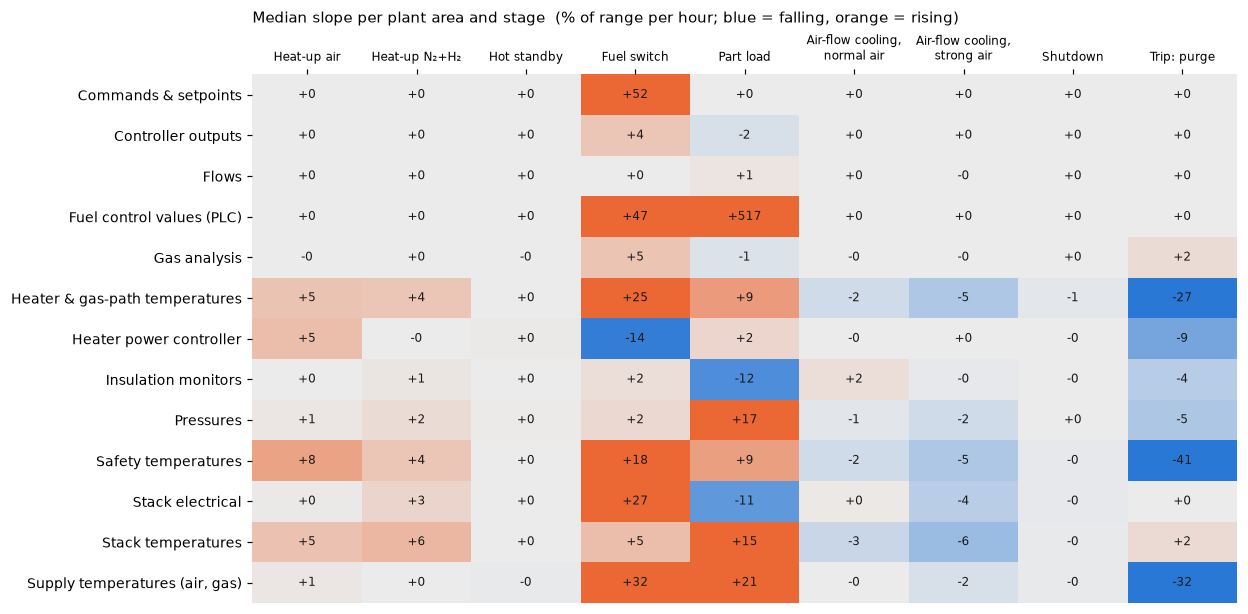

In [12]:
heat(L.pivot_table(index="area", columns="group", values="pct_of_range_per_h", aggfunc="median")
      .reindex(columns=[g for g in sj.GROUPS if g in set(L.group)]),
     "Median slope per plant area and stage", lim=15, note="% of range per hour")

Fastest-moving columns per stage (largest |% of range per hour| among columns that move in that stage):

In [13]:
top = (L[L.moves].assign(abs_pct=lambda x: x.pct_of_range_per_h.abs())
       .sort_values("abs_pct", ascending=False).groupby("group").head(5)
       .sort_values(["group", "abs_pct"], ascending=[True, False]))
top[["group", "col", "area", "median_per_h", "pct_of_range_per_h", "runs"]].round(2)

,group,col,area,median_per_h,pct_of_range_per_h,runs
2934,"Air-flow cooling, normal air",pi_EIRC_2_01_ActV_rMas_Voltage_[V],Heater power controller,-224.59,-48.26,1
2871,"Air-flow cooling, normal air",pi_EIRC_2_01_ActV_rMas_ActValue_[%],Heater power controller,-64.67,-47.46,1
171,"Air-flow cooling, normal air",B2_0x2028(ohTestStat)_Udc_To_PE/[V],Insulation monitors,8.36,13.58,5
2925,"Air-flow cooling, normal air",pi_EIRC_2_01_ActV_rMas_VoltInput_[V],Heater power controller,0.00,9.00,1
45,"Air-flow cooling, normal air",B0_0x2028(ohTestStat)_Udc_To_PE/[V],Insulation monitors,3.31,7.53,5
1090,"Air-flow cooling, strong air",PLC_ctrl_ct_FIRC_113_PV_ProcessValue,Heater & gas-path temperatures,2.40,8.11,2
3223,"Air-flow cooling, strong air",pi_EIR_4_5_22,Stack electrical,67.40,7.05,5
2521,"Air-flow cooling, strong air",TotalVoltage_M5,Stack electrical,-34.69,-6.85,4
3205,"Air-flow cooling, strong air",pi_EIR_4_5_18,Stack electrical,-8.05,-6.39,5
2260,"Air-flow cooling, strong air",TIR_4_6_31,Stack temperatures,-41.11,-6.35,5


## 5. Stage borders: bend, acceleration and jerk

Every stage change with ±40 min of stack data. A border is **clean** if the stage on each side lasts at least 10 min.
Per border and signal: slope before / after (30-min lines), bend, step (mean +5…+15 min minus mean −15…−5 min),
peak speed, acceleration and jerk within ±15 min, and for the stack the bend time (10 → 90 %).

In [14]:
bt = sj.border_table(d)
bt.to_csv(OUT / "border_bends.csv", index=False)
print(bt.time.nunique(), "borders,", bt[bt.clean].time.nunique(), "clean")
st = bt[(bt.signal == "Stack T") & bt.clean]
st.groupby(["frm", "to"]).agg(borders=("bend", "size"), before=("before", "median"), after=("after", "median"),
                              bend=("bend", "median"), bend_time_min=("stack_bend_time_min", "median"),
                              accel_max=("accel_max", "median"), jerk_max=("jerk_max", "median")).round(1)

131 borders, 64 clean


borders  before  after   bend  bend_time_min  accel_max  jerk_max
frm              to                                                                                 
Air-flow cooling Heat-up N₂+H₂           1    -7.7   13.8   21.4           32.0        3.0       1.0
                 Heat-up air             2     0.2    8.2    8.0           20.0        1.3       0.3
                 Shutdown                7    -4.8    0.0    5.8            3.5        6.1       2.2
Fuel switch      Hot standby             1     5.9  -11.9  -17.8           19.0        4.0       1.1
                 Part load               4    17.0  113.7   86.0           10.0        9.1       1.3
Heat-up N₂+H₂    Air-flow cooling        1     1.7   -9.9  -11.5           28.0        1.0       0.2
                 Heat-up air             1    19.8   11.4   -8.4           34.0        0.9       0.2
                 Hot standby             8     6.6    4.2   -2.3            NaN        0.5       0.2
                 Shutdown                1    66.5    5.3  -61.1            3.0       65.4      23.5
Heat-up air      Air-flow cooling        1    -9.6  -29.8  -20.2           10.0       11.5       3.1
                 Heat-up N₂+H₂          10    51.0   55.9    7.0           18.0        1.6       0.3
                 Shutdown                1    15.9    2.7  -13.2            0.0       51.7      20.5
Hot standby      Air-flow cooling        5    -1.4  -25.5  -24.0           31.0        1.8       0.4
                 Fuel switch             8     0.3   37.7   34.0           17.0        4.6       1.1
Part load        Air-flow cooling        1   141.7  -54.8 -196.5            9.0       29.6       5.2
                 Fuel switch             1    48.3   45.6   -2.8            6.0        6.7       2.1
                 Trip: purge             1   125.0  -37.0 -161.9            9.0       23.4       4.1
Shutdown         Air-flow cooling        4    -0.3   -0.3    0.1           14.0        1.3       0.4
                 Heat-up air             2    -1.5  -16.9  -15.4           16.5        5.4       1.8
                 Hot standby             1    34.4   34.6    0.3            NaN       16.9       5.4
Trip: purge      Air-flow cooling        2    78.1  -29.7 -107.7            9.5       16.2       2.4
                 Hot standby             1    -4.3  -46.1  -41.8            2.0        8.9       2.8

Stack against the heaters (mean of EAGH, EAOH1, EAOH2) at the same clean borders: the heaters bend and jerk far harder
than the stack.

In [15]:
cmp = (bt[bt.clean & bt.signal.isin(["Stack T", "Heaters T"])]
       .groupby(["frm", "to", "signal"])[["before", "after", "accel_max", "jerk_max"]].median().unstack("signal").round(1))
cmp

before             after         accel_max          jerk_max        
signal                            Heaters T Stack T Heaters T Stack T Heaters T Stack T Heaters T Stack T
frm              to                                                                                      
Air-flow cooling Heat-up N₂+H₂         -6.2    -7.7      -5.8    13.8       0.7     3.0       0.2     1.0
                 Heat-up air           21.0     0.2     277.2     8.2      46.9     1.3       7.9     0.3
                 Shutdown              -5.9    -4.8      -0.4     0.0       7.9     6.1       2.8     2.2
Fuel switch      Hot standby          -89.9     5.9    -102.7   -11.9      43.4     4.0      15.2     1.1
                 Part load             33.8    17.0      16.0   113.7      42.6     9.1      12.6     1.3
Heat-up N₂+H₂    Air-flow cooling     -52.5     1.7     -16.2    -9.9       2.4     1.0       0.2     0.2
                 Heat-up air           23.1    19.8      51.0    11.4      73.6     0.9      23.4     0.2
                 Hot standby           11.2     6.6       9.5     4.2       0.4     0.5       0.1     0.2
                 Shutdown             -87.0    66.5    -129.8     5.3      54.9    65.4       9.8    23.5
Heat-up air      Air-flow cooling    -148.1    -9.6     -61.4   -29.8       5.4    11.5       0.4     3.1
                 Heat-up N₂+H₂         30.6    51.0     -64.2    55.9      30.4     1.6       7.3     0.3
                 Shutdown              -7.9    15.9    -122.1     2.7     212.2    51.7      76.8    20.5
Hot standby      Air-flow cooling     -87.0    -1.4     -39.8   -25.5      18.2     1.8       3.7     0.4
                 Fuel switch           -0.7     0.3      81.8    37.7      40.2     4.6      10.8     1.1
Part load        Air-flow cooling      46.6   141.7    -120.5   -54.8      27.0    29.6       4.9     5.2
                 Fuel switch           44.9    48.3    -142.7    45.6      49.9     6.7       7.9     2.1
                 Trip: purge          -44.9   125.0    -199.3   -37.0      56.1    23.4      11.6     4.1
Shutdown         Air-flow cooling      -0.2    -0.3     170.7    -0.3      46.9     1.3      10.9     0.4
                 Heat-up air           -3.5    -1.5     298.9   -16.9      63.7     5.4      14.0     1.8
                 Hot standby         -109.4    34.4     171.6    34.6      28.4    16.9       7.1     5.4
Trip: purge      Air-flow cooling    -103.2    78.1     -20.5   -29.7      56.5    16.2      14.1     2.4
                 Hot standby         -108.9    -4.3     -49.1   -46.1      38.8     8.9      11.7     2.8

### 5.1 Typical curve per border type

Median over the clean borders of each type, −45 to +60 min; temperatures as change from the value at the border.
Bend time = the median curve's smoothed slope going 10 → 90 % from the old to the new slope.

In [16]:
ty, curves = sj.border_type_curves(d)
ty.to_csv(OUT / "border_type_bends.csv", index=False)
import json
json.dump(curves, open(OUT / "border_type_curves.json", "w", encoding="utf-8"), ensure_ascii=False)
ty[ty.signal.isin(["T_stack_C", "T_heaters_C"])].round(1)

,frm,to,borders,signal,before,after,bend,bend_t10_min,bend_t90_min,bend_time_min
0,Shutdown,Heat-up air,2,T_stack_C,-1.5,-16.9,-15.4,10.0,14.0,4.0
1,Shutdown,Heat-up air,2,T_heaters_C,-3.5,298.9,302.4,0.0,8.0,8.0
7,Heat-up air,Heat-up N₂+H₂,10,T_stack_C,51.2,55.2,4.0,NaN,NaN,NaN
8,Heat-up air,Heat-up N₂+H₂,10,T_heaters_C,30.7,-63.9,-94.6,-3.0,1.0,4.0
14,Heat-up N₂+H₂,Shutdown,1,T_stack_C,66.5,5.3,-61.1,-5.0,-5.0,0.0
15,Heat-up N₂+H₂,Shutdown,1,T_heaters_C,-87.0,-129.8,-42.8,-13.0,-12.0,1.0
21,Shutdown,Air-flow cooling,4,T_stack_C,-0.3,-0.3,-0.0,NaN,NaN,NaN
22,Shutdown,Air-flow cooling,4,T_heaters_C,-0.2,184.9,185.1,1.0,6.0,5.0
28,Air-flow cooling,Heat-up air,2,T_stack_C,0.2,8.2,8.0,-6.0,16.0,22.0
29,Air-flow cooling,Heat-up air,2,T_heaters_C,21.0,277.2,256.2,-8.0,-2.0,6.0


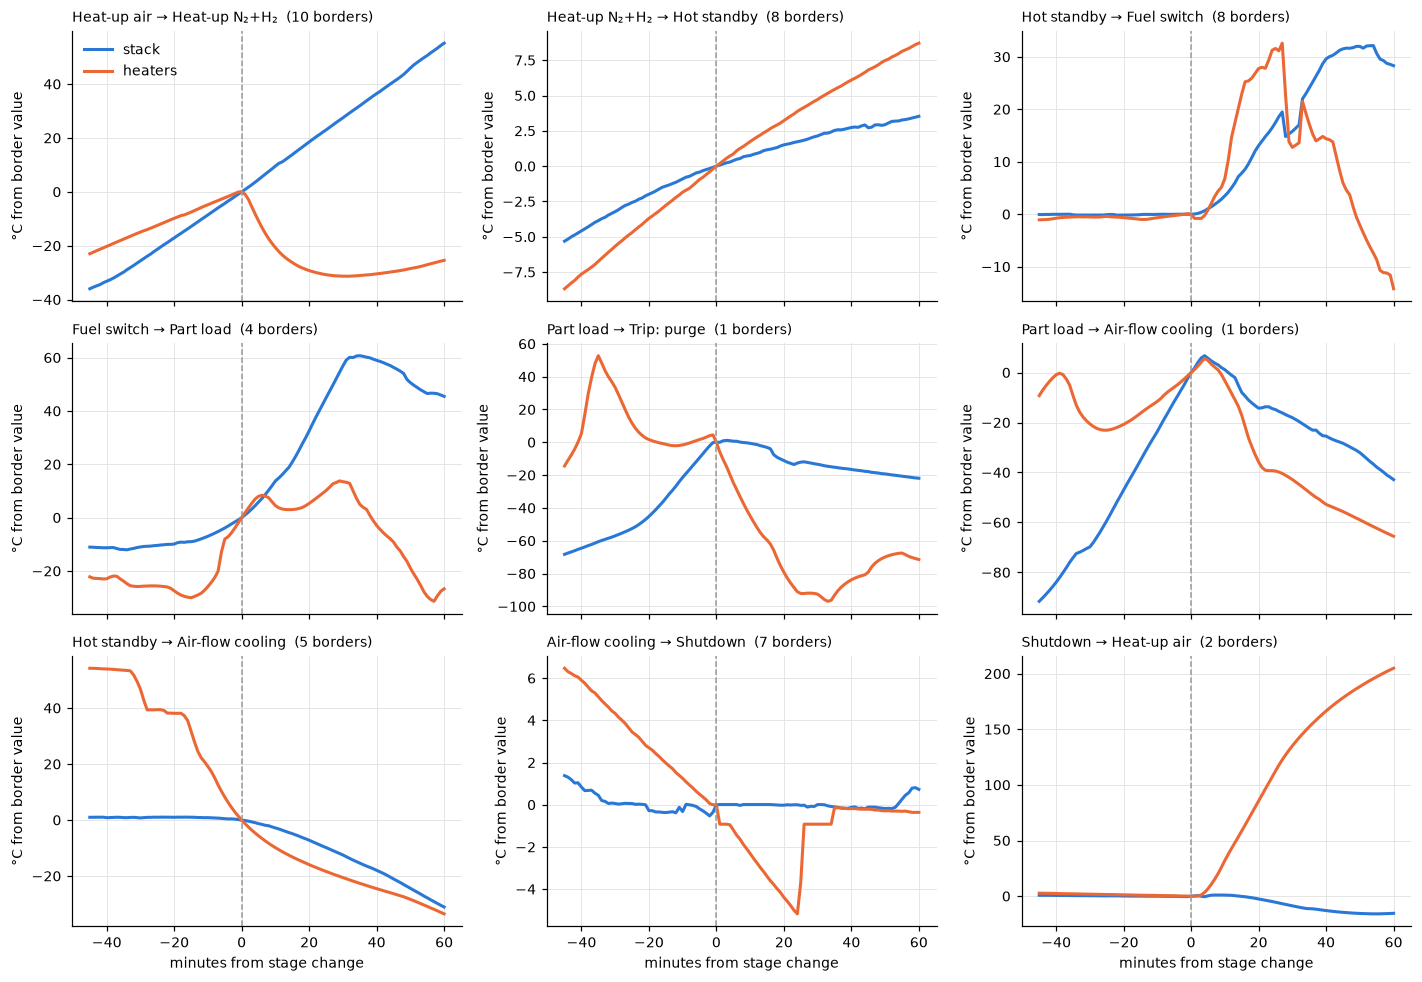

In [17]:
KEYS = [(sj.HEAT_AIR, sj.HEAT_FG), (sj.HEAT_FG, sj.HS), (sj.HS, sj.FS), (sj.FS, sj.PL), (sj.PL, sj.PURGE),
        (sj.PL, sj.AFC), (sj.HS, sj.AFC), (sj.AFC, sj.SD), (sj.SD, sj.HEAT_AIR)]
tm = np.array(curves["minutes"])
fig, axs = plt.subplots(3, 3, figsize=(13, 9), sharex=True)
for ax, (a, b) in zip(axs.flat, KEYS):
    c = curves["curves"].get(f"{a} > {b}", {})
    n = ty[(ty.frm == a) & (ty.to == b)].borders.max()
    for col, color, lab in (("T_stack_C", BLUE, "stack"), ("T_heaters_C", ORANGE, "heaters")):
        if col in c:
            ax.plot(tm, np.array(c[col], dtype=float), color=color, label=lab)
    ax.axvline(0, color="#999", lw=1, ls="--")
    ax.set_title(f"{a} → {b}  ({n if n == n else 0} borders)", loc="left", fontsize=9)
    ax.set_ylabel("°C from border value")
for ax in axs[-1]:
    ax.set_xlabel("minutes from stage change")
axs[0, 0].legend(frameon=False)
fig.tight_layout()
plt.show()

## 6. Leaving hot standby

Every exit from *Hot standby* except to *Fuel switch* (that is the way to load). Slope over the last hour before, the
first 30 min / 1 h / 3 h after, air flow per hour, and hours until the stack has dropped 50 / 100 / 200 / 300 °C.
`real_cooldown` = the next stage lasts ≥ 20 min and the stack is > 5 °C lower after 1 h; the two short *Shutdown*
blocks (2026-03-13, 27 min; 2026-03-23, 4 min) are label blips, not cool-downs.

In [18]:
ex = sj.stage_exits(d)
ex.to_csv(OUT / "hot_standby_exits.csv", index=False)
ex.round(1)

,time,to,next_minutes,T_start_C,slope_last_1h,slope_first_30min,slope_first_60min,slope_first_180min,air_h0,air_h1,air_h2,air_h4,h_to_drop_50C,h_to_drop_100C,h_to_drop_200C,h_to_drop_300C,next_stage_slope,real_cooldown
0,2026-02-04 02:01:00,Air-flow cooling,3319,508.9,-0.5,-25.2,-29.9,-27.1,5999.8,5999.9,6000.0,6000.0,1.8,4.0,9.0,16.7,-7.1,True
1,2026-02-16 10:37:00,Air-flow cooling,1263,509.6,-0.2,-25.7,-29.5,-26.8,6000.1,6000.2,5999.9,6000.2,1.8,4.0,10.0,21.0,-13.7,True
2,2026-02-18 17:26:00,Air-flow cooling,28,600.4,0.8,-14.3,-14.3,-22.6,6000.1,5999.5,6000.1,6000.0,2.4,4.2,NaN,NaN,-14.3,True
3,2026-03-04 17:56:00,Air-flow cooling,364,613.6,-0.2,-24.4,-32.2,-52.2,8000.1,8000.0,7999.9,8000.0,1.4,2.2,4.1,NaN,-50.0,True
4,2026-03-13 10:15:00,Shutdown,27,520.2,10.6,6.7,33.3,21.7,5998.9,6000.0,5999.9,6000.0,0.3,0.3,NaN,NaN,-2.2,False
5,2026-03-20 16:24:00,Air-flow cooling,456,572.2,16.8,-36.6,-52.6,-66.6,9999.7,10000.2,10000.1,10001.2,1.0,1.6,3.4,NaN,-40.6,True
6,2026-03-23 08:40:00,Shutdown,4,518.3,NaN,35.4,9.2,-4.3,19.4,10000.0,9999.2,9998.5,0.0,0.0,NaN,NaN,-735.1,False
7,2026-03-25 10:59:00,Trip: purge,15,660.1,58.9,-39.7,-44.7,-34.0,9578.8,9484.8,9538.6,6065.0,1.1,6.1,7.9,9.8,-43.3,False
8,2026-03-29 02:00:00,No data,60,503.5,4.1,NaN,NaN,2.2,5999.8,6000.0,6000.0,6000.0,38.3,39.2,41.4,NaN,NaN,False
9,2026-03-30 13:33:00,Air-flow cooling,444,626.8,5.0,-36.8,-47.2,-68.8,6000.1,8000.0,7999.9,8000.0,1.1,1.7,3.2,5.2,-53.7,True


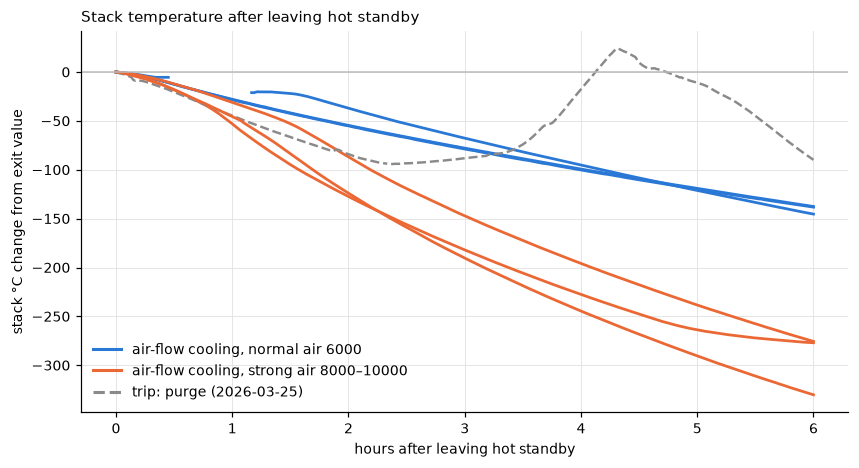

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for r in ex.itertuples():
    if not (r.real_cooldown or r.to == sj.PURGE):
        continue
    seg = d.T_stack_C[r.time:r.time + pd.Timedelta("6h")]
    h = (seg.index - r.time).total_seconds() / 3600
    if r.to == sj.PURGE:
        ax.plot(h, seg - r.T_start_C, color=GRAY, ls="--", lw=1.6)
    else:
        ax.plot(h, seg - r.T_start_C, color=ORANGE if r.air_h1 >= sj.STRONG_AIR else BLUE, lw=1.8)
ax.plot([], [], color=BLUE, label="air-flow cooling, normal air 6000")
ax.plot([], [], color=ORANGE, label="air-flow cooling, strong air 8000–10000")
ax.plot([], [], color=GRAY, ls="--", label="trip: purge (2026-03-25)")
ax.axhline(0, color="#bbb", lw=1)
ax.set(xlabel="hours after leaving hot standby", ylabel="stack °C change from exit value")
ax.set_title("Stack temperature after leaving hot standby", loc="left", fontsize=10)
ax.legend(frameon=False, loc="lower left")
plt.show()

In [20]:
real = ex[ex.real_cooldown].assign(air=lambda x: np.where(x.air_h1 >= sj.STRONG_AIR, "strong 8000–10000", "normal 6000"))
real.groupby("air")[["slope_first_30min", "slope_first_60min", "slope_first_180min", "h_to_drop_100C"]].agg(["median", "min", "max"]).round(1)

slope_first_30min             slope_first_60min             slope_first_180min             h_to_drop_100C          
                             median   min   max            median   min   max             median   min   max         median  min  max
air                                                                                                                                  
normal 6000                   -25.2 -25.7 -14.3             -29.5 -29.9 -14.3              -26.8 -27.1 -22.6            4.0  4.0  4.2
strong 8000–10000             -36.6 -36.8 -24.4             -47.2 -52.6 -32.2              -66.6 -68.8 -52.2            1.7  1.6  2.2

**Reading:** before the exit the stack is flat (±1 °C/h). With normal air it falls about 25–30 °C/h in the first hours
(100 °C in about 4 h); with strong air the fall speeds up from about −30 to −50…−70 °C/h within 3 h (100 °C in about
2 h). An air-off shutdown cools only about −2 °C/h (§1).